In [ ]:
!unzip data.zip

Output streaming troncato alle ultime 5000 righe.
  inflating: masks/frame_001_mask.png  
  inflating: masks/frame_002_mask.png  
  inflating: masks/frame_003_mask.png  
  inflating: masks/frame_004_mask.png  
  inflating: masks/frame_005_mask.png  
  inflating: masks/frame_006_mask.png  
  inflating: masks/frame_007_mask.png  
  inflating: masks/frame_008_mask.png  
  inflating: masks/frame_009_mask.png  
  inflating: masks/frame_010_mask.png  
  inflating: masks/frame_011_mask.png  
  inflating: masks/frame_012_mask.png  
  inflating: masks/frame_013_mask.png  
  inflating: masks/frame_014_mask.png  
  inflating: masks/frame_015_mask.png  
  inflating: masks/frame_016_mask.png  
  inflating: masks/frame_017_mask.png  
  inflating: masks/frame_018_mask.png  
  inflating: masks/frame_019_mask.png  
  inflating: masks/frame_020_mask.png  
  inflating: masks/frame_021_mask.png  
  inflating: masks/frame_022_mask.png  
  inflating: masks/frame_023_mask.png  
  inflating: masks/frame_024_m

# Phase 1 – Segmentation Training

In this phase, we train a **binary segmentation model** to isolate droplet regions from input RGB frames using a lightweight DeepLabV3+ architecture with MobileNetV3-Large.

### 🧱 Architecture
- **Backbone**: MobileNetV3-Large (pretrained)
- **Output**: Binary mask (1 channel)
- **Resolution**: 320×240 (keeps 4:3 aspect ratio)

#### **Imports**

In [61]:
import os
import cv2
import time
import torch
import joblib
import numpy as np
import pandas as pd
import albumentations as A
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from torchvision.models.segmentation import deeplabv3_mobilenet_v3_large
from albumentations.pytorch import ToTensorV2

# Set current working directory to the script's directory
os.chdir(os.path.abspath(""))


#### **Configuration and Dataset Definition**

In [ ]:
SEED = 42
NUM_CLASSES = 1
BATCH_SIZE = 8
NUM_EPOCHS = 30
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMAGE_DIR = "./frames"
MASK_DIR = "./masks"

seg_transform = A.Compose([
    A.Resize(240, 320),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2()
])


class DropletDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.images = os.listdir(image_dir)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        mask_name = img_name.rsplit(".", 1)[0] + "_mask." + img_name.rsplit(".", 1)[1]
        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, mask_name)

        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        return image, mask.unsqueeze(0)

cuda


#### **Training**

In [ ]:
train_set, test_set = random_split(DropletDataset(IMAGE_DIR, MASK_DIR, seg_transform), [int(0.8*len(os.listdir(IMAGE_DIR))), len(os.listdir(IMAGE_DIR)) - int(0.8*len(os.listdir(IMAGE_DIR)))])
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

model = deeplabv3_mobilenet_v3_large(pretrained=True)
model.classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)
model = model.to(DEVICE)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)
scaler = torch.amp.GradScaler()

best_iou = 0
iou_history, dice_history, loss_history = [], [], []

best_loss = float("inf")
patience_counter = 0
early_stopping_patience = 5

for epoch in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    for images, masks in tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS}"):
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        optimizer.zero_grad()
        with torch.amp.autocast(device_type='cuda'):
            outputs = model(images)["out"]
            loss = criterion(outputs, masks)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    scheduler.step(avg_loss)

    model.eval()
    iou_scores, dice_scores = [], []
    with torch.no_grad():
        for images, masks in test_loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            outputs = model(images)["out"]
            preds = (torch.sigmoid(outputs) > 0.5).float()
            for i in range(len(images)):
                pred = preds[i].view(-1).bool()
                target = masks[i].view(-1).bool()
                intersection = (pred & target).sum().item()
                union = (pred | target).sum().item()
                iou = intersection / union if union != 0 else float('nan')
                dice = (2 * intersection) / (pred.sum().item() + target.sum().item() + 1e-8)
                if not np.isnan(iou): iou_scores.append(iou)
                dice_scores.append(dice)

    mean_iou = np.mean(iou_scores)
    mean_dice = np.mean(dice_scores)
    iou_history.append(mean_iou)
    dice_history.append(mean_dice)
    loss_history.append(avg_loss)

    if avg_loss < best_loss:
        best_loss = avg_loss
        patience_counter = 0
        torch.save(model.state_dict(), "best_segmentation_model.pth")
        print(f"Saved best model (loss = {avg_loss:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= early_stopping_patience:
            print(f"Early stopping at epoch {epoch+1} (no improvement for {early_stopping_patience} epochs)")
            break

/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=DeepLabV3_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1`. You can also use `weights=DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/deeplabv3_mobilenet_v3_large-fc3c493d.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_mobilenet_v3_large-fc3c493d.pth
100%|██████████| 42.3M/42.3M [00:00<00:00, 153MB/s]
Epoch 1/30: 100%|██████████| 500/500 [01:03<00:00,  7.82it/s]


✅ Saved best model (loss = 0.0176)


Epoch 2/30: 100%|██████████| 500/500 [00:57<00:00,  8.65it/s]


✅ Saved best model (loss = 0.0053)


Epoch 3/30: 100%|██████████| 500/500 [00:58<00:00,  8.59it/s]


...

Epoch 28/30: 100%|██████████| 500/500 [00:56<00:00,  8.87it/s]


✅ Saved best model (loss = 0.0021)


Epoch 29/30: 100%|██████████| 500/500 [00:54<00:00,  9.15it/s]


✅ Saved best model (loss = 0.0021)


Epoch 30/30: 100%|██████████| 500/500 [00:56<00:00,  8.88it/s]


#### **Evaluation**

In [5]:
model.eval()
all_preds_seg, all_targets_seg = [], []
with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        outputs = model(images)["out"]
        preds = (torch.sigmoid(outputs) > 0.5).float()
        all_preds_seg.append(preds.cpu())
        all_targets_seg.append(masks.cpu())

# Flatten predictions and masks
all_preds_seg = torch.cat(all_preds_seg, dim=0)
all_targets_seg = torch.cat(all_targets_seg, dim=0)

# Save segmentation training log
pd.DataFrame({
    "epoch": list(range(1, NUM_EPOCHS + 1)),
    "loss": loss_history,
    "iou": iou_history,
    "dice": dice_history
}).to_csv("segmentation_training_log.csv", index=False)
print("📄 Training log saved to segmentation_training_log.csv")


📄 Training log saved to segmentation_training_log.csv


#### **Plots**

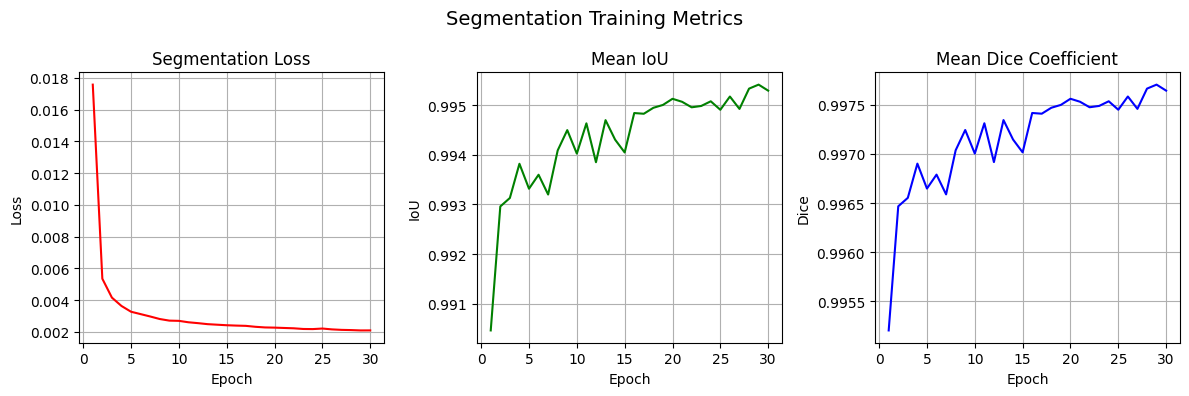

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Load training logs
seg_log = pd.read_csv("segmentation_training_log.csv")


plt.figure(figsize=(12, 4))
plt.suptitle("Segmentation Training Metrics", fontsize=14)

plt.subplot(1, 3, 1)
plt.plot(seg_log["epoch"], seg_log["loss"], label="Loss", color="red")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Segmentation Loss")
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(seg_log["epoch"], seg_log["iou"], label="IoU", color="green")
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("Mean IoU")
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(seg_log["epoch"], seg_log["dice"], label="Dice", color="blue")
plt.xlabel("Epoch")
plt.ylabel("Dice")
plt.title("Mean Dice Coefficient")
plt.grid(True)

plt.tight_layout()
plt.show()


# Phase 2 – Regression

In this phase, we train a CNN regressor that takes a droplet binary mask and predicts 12 geometric features (contact angles, ellipse parameters, bounding box, and volume).

### 🧱 Architecture
- **Input**: Binary droplet mask 240×320 (4:3)
- **Backbone**: Custom CNN with 3 conv layers and 2 linear layers
- **Output**: 12 regression values

#### **Imports**

In [3]:
from PIL import Image
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler

#### **Regressor Definition**

In [7]:
class DropletCNNRegressor(nn.Module):
    def __init__(self):
        super(DropletCNNRegressor, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(128 * 60 * 80, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 12)
        )

    def forward(self, x):
        return self.net(x)

#### **Configuration and Dataset Definition**

In [8]:
REG_MASK_DIR = MASK_DIR
REG_CSV_PATH = "./analysis.csv"

reg_transform = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.Resize((240, 320)),
    transforms.ToTensor()
])

class DropletRegressionDataset(Dataset):
    def __init__(self, mask_dir, df, scaled_labels, transform=None):
        self.mask_dir = mask_dir
        self.df = df.reset_index(drop=True)
        self.scaled_labels = scaled_labels
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        frame_code = int(self.df.iloc[idx]["Frame"])
        mask_path = os.path.join(self.mask_dir, f"frame_{frame_code:03d}_mask.png")
        mask = Image.open(mask_path).convert("L")
        if self.transform:
            mask = self.transform(mask)
        else:
            mask = torch.tensor(np.array(mask), dtype=torch.float32).unsqueeze(0) / 255.0
        label = self.scaled_labels[idx]
        return mask, torch.tensor(label, dtype=torch.float32)


#### **Data Preparation**

In [9]:
df = pd.read_csv(REG_CSV_PATH)
df = df[df.Valid != 'False'].drop(columns=["Volume_Loss", "Valid"]).dropna()
labels_np = df.iloc[:, 1:].values
scaler = StandardScaler()
scaled_labels = scaler.fit_transform(labels_np)
joblib.dump(scaler, "scaler.joblib")

reg_dataset = DropletRegressionDataset(REG_MASK_DIR, df, scaled_labels, reg_transform)
reg_train_size = int(0.8 * len(reg_dataset))
reg_test_size = len(reg_dataset) - reg_train_size
reg_train_set, reg_test_set = random_split(reg_dataset, [reg_train_size, reg_test_size])
reg_train_loader = DataLoader(reg_train_set, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
reg_test_loader = DataLoader(reg_test_set, batch_size=16, shuffle=False, num_workers=4, pin_memory=True)


#### **Training**

In [ ]:
reg_model = DropletCNNRegressor().to(DEVICE)
reg_criterion = nn.SmoothL1Loss()
reg_optimizer = optim.Adam(reg_model.parameters(), lr=1e-4)
reg_scheduler = optim.lr_scheduler.ReduceLROnPlateau(reg_optimizer, mode='min', patience=2, factor=0.5, verbose=True)

num_epochs = 20
reg_patience = 3
best_val_loss = float('inf')
patience_counter = 0
train_losses, val_losses, val_r2_scores = [], [], []
start_time = time.time()

for epoch in range(num_epochs):
    reg_model.train()
    total_loss = 0.0
    for images, labels in tqdm(reg_train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        reg_optimizer.zero_grad()
        outputs = reg_model(images)
        loss = reg_criterion(outputs, labels)
        loss.backward()
        reg_optimizer.step()
        total_loss += loss.item()
    avg_train_loss = total_loss / len(reg_train_loader)
    train_losses.append(avg_train_loss)

    reg_model.eval()
    val_loss, all_preds, all_labels = 0.0, [], []
    with torch.no_grad():
        for images, labels in reg_test_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = reg_model(images)
            loss = reg_criterion(outputs, labels)
            val_loss += loss.item()
            all_preds.append(outputs.cpu().numpy())
            all_labels.append(labels.cpu().numpy())
    avg_val_loss = val_loss / len(reg_test_loader)
    val_losses.append(avg_val_loss)
    reg_scheduler.step(avg_val_loss)
    preds_np = np.vstack(all_preds)
    targets_np = np.vstack(all_labels)
    val_r2 = r2_score(targets_np, preds_np)
    val_r2_scores.append(val_r2)
    print(f"Epoch [{epoch+1}/{num_epochs}] - Train Loss: {avg_train_loss:.4f} - Val Loss: {avg_val_loss:.4f} - Val R²: {val_r2:.4f}")
    torch.save(reg_model.state_dict(), "cnn_regressor_last.pth")
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= reg_patience:
            print(f"Early stopping at epoch {epoch+1}")
            break

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
Epoch 1/20 [Train]: 100%|██████████| 125/125 [00:41<00:00,  3.01it/s]


Epoch [1/20] - Train Loss: 0.2023 - Val Loss: 0.0749 - Val R²: 0.7596


Epoch 2/20 [Train]:   0%|          | 0/125 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Epoch 2/20 [Train]: 100%|██████████| 125/125 [00:41<00:00,  2.99it/s]


Epoch [2/20] - Train Loss: 0.0853 - Val Loss: 0.0439 - Val R²: 0.8424


Epoch 3/20 [Train]:   0%|          | 0/125 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Epoch 3/20 [Train]: 100%|██████████| 125/125 [00:42<00:00,  2.91it/s]


...

Epoch [13/20] - Train Loss: 0.0301 - Val Loss: 0.0191 - Val R²: 0.8969


Epoch 14/20 [Train]:   0%|          | 0/125 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Epoch 14/20 [Train]: 100%|██████████| 125/125 [00:42<00:00,  2.92it/s]


Epoch [14/20] - Train Loss: 0.0282 - Val Loss: 0.0183 - Val R²: 0.8986


Epoch 15/20 [Train]:   0%|          | 0/125 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
Epoch 15/20 [Train]: 100%|██████████| 125/125 [00:42<00:00,  2.96it/s]


Epoch [15/20] - Train Loss: 0.0284 - Val Loss: 0.0163 - Val R²: 0.9029
Early stopping at epoch 15


#### **Save Model**

In [ ]:
torch.save(reg_model.state_dict(), "cnn_regressor_best.pth")

#### **Evaluation**

In [ ]:
reg_model.eval()
all_preds, all_targets = [], []
with torch.no_grad():
    for images, labels in reg_test_loader:
        images = images.to(DEVICE)
        outputs = reg_model(images).cpu().numpy()
        labels = labels.cpu().numpy()
        all_preds.append(outputs)
        all_targets.append(labels)
all_preds = np.vstack(all_preds)
all_targets = np.vstack(all_targets)
mae = mean_absolute_error(all_targets, all_preds)
mse = mean_squared_error(all_targets, all_preds)
r2 = r2_score(all_targets, all_preds)
print(f"\nFinal Evaluation:\n  MAE = {mae:.4f}\n  MSE = {mse:.4f}\n  R²  = {r2:.4f}")

# Save training log
pd.DataFrame({"epoch": list(range(1, len(train_losses) + 1)), "train_loss": train_losses, "val_loss": val_losses, "val_r2": val_r2_scores}).to_csv("regression_training_log.csv", index=False)
print("📄 Training log saved to regression_training_log.csv")

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(



Final Evaluation:
  MAE = 0.0936
  MSE = 0.1076
  R²  = 0.9026
📄 Training log saved to regression_training_log.csv


#### **Plots**

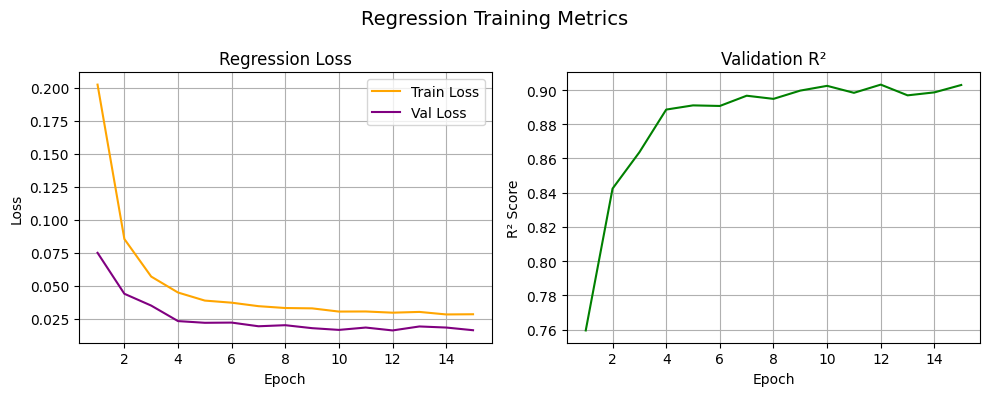

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load training logs
reg_log = pd.read_csv("regression_training_log.csv")

plt.figure(figsize=(10, 4))
plt.suptitle("Regression Training Metrics", fontsize=14)

plt.subplot(1, 2, 1)
plt.plot(reg_log["epoch"], reg_log["train_loss"], label="Train Loss", color="orange")
plt.plot(reg_log["epoch"], reg_log["val_loss"], label="Val Loss", color="purple")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Regression Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(reg_log["epoch"], reg_log["val_r2"], label="Val R²", color="green")
plt.xlabel("Epoch")
plt.ylabel("R² Score")
plt.title("Validation R²")
plt.grid(True)

plt.tight_layout()
plt.show()

# Phase 3 – Multi-Task DropNET

In this phase, we fine-tune the full segmentation + regression pipeline end-to-end.
The architecture combines the trained DeepLabV3+ model with a CNN regressor, taking predicted masks and producing geometric outputs.

### 🧱 Architecture
- **Encoder**: DeepLabV3+ MobileNetV3 (pretrained weights from Phase 1)
- **Geometric Head**: CNN regressor (weights from Phase 2)
- **Input**: RGB image
- **Internal Flow**: image → predicted mask → geometric regression
- **Output**: 12 geometric values (contact angles, ellipse params, bounding box, volume)


#### **DropNET Architecture**

In [10]:
class DropNET(nn.Module):
    def __init__(self, seg_model, regressor_head):
        super(DropNET, self).__init__()
        self.seg_model = seg_model
        self.reg_head = regressor_head

    def forward(self, x):
        seg_out = self.seg_model(x)["out"]
        prob_mask = torch.sigmoid(seg_out)
        binary_mask = (prob_mask > 0.5).float()
        resized_mask = F.interpolate(binary_mask, size=(240, 320), mode='bilinear', align_corners=False)
        reg_out = self.reg_head(resized_mask)
        return seg_out, reg_out

#### **Dataset Definition and Configuration**

In [11]:
seg_transform = A.Compose([
    A.Resize(240, 320),
    A.Normalize(mean=(0.5,), std=(0.5,)),
    ToTensorV2()
])

class MultiTaskDropletDataset(Dataset):
    def __init__(self, image_dir, mask_dir, csv_path, scaler, transform):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.df = pd.read_csv(csv_path)
        self.df = self.df[(self.df.Valid != 'False')].drop(columns=["Volume_Loss", "Valid"]).dropna()
        self.labels = scaler.transform(self.df.iloc[:, 1:].values)
        self.filenames = [f"frame_{int(f):03d}.png" for f in self.df["Frame"]]
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = os.path.join(self.image_dir, self.filenames[idx])
        mask_path = os.path.join(self.mask_dir, self.filenames[idx].replace(".png", "_mask.png"))
        image = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 0).astype(np.float32)
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]
        label = torch.tensor(self.labels[idx], dtype=torch.float32)
        return image, mask.unsqueeze(0), label


LAMBDA = 2.0
NUM_EPOCHS = 40
LR = 5e-5
MT_CSV_PATH = "./analysis.csv"
IMAGE_DIR = "./frames"
MASK_DIR = "./masks"
BATCH_SIZE = 8
scaler = joblib.load("scaler.joblib")
mt_dataset = MultiTaskDropletDataset(IMAGE_DIR, MASK_DIR, MT_CSV_PATH, scaler, seg_transform)
train_size = int(0.8 * len(mt_dataset))
val_size = len(mt_dataset) - train_size
train_set, val_set = random_split(mt_dataset, [train_size, val_size])
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)

#### **Initialization of DropNET with pretrained weights**

In [12]:
seg_model = deeplabv3_mobilenet_v3_large(pretrained=False, aux_loss=True)
seg_model.classifier[4] = nn.Conv2d(256, NUM_CLASSES, kernel_size=1)
seg_model.load_state_dict(torch.load("best_segmentation_model.pth"))

regressor = DropletCNNRegressor()
regressor.load_state_dict(torch.load("cnn_regressor_best.pth"))

model = DropNET(seg_model, regressor).to(DEVICE)

c:\Users\alesa\Desktop\Magistrale\ESILV\Second Semester\PI2\droplet-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\alesa\Desktop\Magistrale\ESILV\Second Semester\PI2\droplet-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to C:\Users\alesa/.cache\torch\hub\checkpoints\mobilenet_v3_large-8738ca79.pth
100%|██████████| 21.1M/21.1M [00:18<00:00, 1.17MB/s]
C:\Users\alesa\AppData\Local\Temp\ipykernel_14960\2079852337.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), wh

#### **Training**

In [ ]:
criterion_seg = nn.BCEWithLogitsLoss()
criterion_reg = nn.SmoothL1Loss()
optimizer = optim.Adam(model.parameters(), lr=LR)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

history = {"loss": [], "val_loss": []}
best_val_loss = float("inf")

for epoch in range(NUM_EPOCHS):
    model.train()
    total_loss = 0
    for imgs, masks, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}"):
        imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        seg_out, reg_out = model(imgs)
        loss = criterion_seg(seg_out, masks) + LAMBDA * criterion_reg(reg_out, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_train_loss = total_loss / len(train_loader)
    history["loss"].append(avg_train_loss)

    model.eval()
    val_loss = 0
    with torch.no_grad():
        for imgs, masks, labels in val_loader:
            imgs, masks, labels = imgs.to(DEVICE), masks.to(DEVICE), labels.to(DEVICE)
            seg_out, reg_out = model(imgs)
            loss = criterion_seg(seg_out, masks) + LAMBDA * criterion_reg(reg_out, labels)
            val_loss += loss.item()
    avg_val_loss = val_loss / len(val_loader)
    history["val_loss"].append(avg_val_loss)
    scheduler.step(avg_val_loss)

    print(f"Epoch [{epoch+1}] - Train Loss: {avg_train_loss:.4f} - Val Loss: {avg_val_loss:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "dropnet_multitask.pth")
        print("✅ Saved best DropNET model.")

# Save training log
pd.DataFrame(history).to_csv("dropnet_training_log.csv", index=False)
print("📄 DropNET training log saved to dropnet_training_log.csv")

Epoch 1: 100%|██████████| 497/497 [02:16<00:00,  3.63it/s]


Epoch [1] - Train Loss: 0.0571 - Val Loss: 0.0304
✅ Saved best DropNET model.


Epoch 2: 100%|██████████| 497/497 [02:15<00:00,  3.66it/s]


Epoch [2] - Train Loss: 0.0565 - Val Loss: 0.0308


Epoch 3: 100%|██████████| 497/497 [02:15<00:00,  3.67it/s]


...

Epoch 17: 100%|██████████| 497/497 [02:15<00:00,  3.68it/s]


Epoch [17] - Train Loss: 0.0448 - Val Loss: 0.0400


Epoch 18: 100%|██████████| 497/497 [02:15<00:00,  3.68it/s]


Epoch [18] - Train Loss: 0.0448 - Val Loss: 0.0375


Epoch 19:  96%|█████████▌| 477/497 [02:09<00:05,  3.75it/s]

#### **Evaluation**

In [13]:
model.load_state_dict(torch.load("dropnet_multitask.pth"))
model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for imgs, _, labels in tqdm(val_loader):
        imgs = imgs.to(DEVICE)
        _, reg_out = model(imgs)
        all_preds.append(reg_out.cpu().numpy())
        all_labels.append(labels.numpy())

all_preds = np.vstack(all_preds)
all_labels = np.vstack(all_labels)
mae = mean_absolute_error(all_labels, all_preds)
mse = mean_squared_error(all_labels, all_preds)
r2 = r2_score(all_labels, all_preds)

print("\n📊 DropNET Evaluation:")
print(f"  MAE  = {mae:.4f}")
print(f"  MSE  = {mse:.4f}")
print(f"  R²   = {r2:.4f}")

C:\Users\alesa\AppData\Local\Temp\ipykernel_14960\2389012299.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("dropnet_multitask.pth"))
1


📊 DropNET Evaluation:
  MAE  = 0.0862
  MSE  = 0.0909
  R²   = 0.9060


#### **Inference and Results visualization**

c:\Users\alesa\Desktop\Magistrale\ESILV\Second Semester\PI2\droplet-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\alesa\Desktop\Magistrale\ESILV\Second Semester\PI2\droplet-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\alesa\AppData\Local\Temp\ipykernel_14960\1460768526.py:71: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#unt

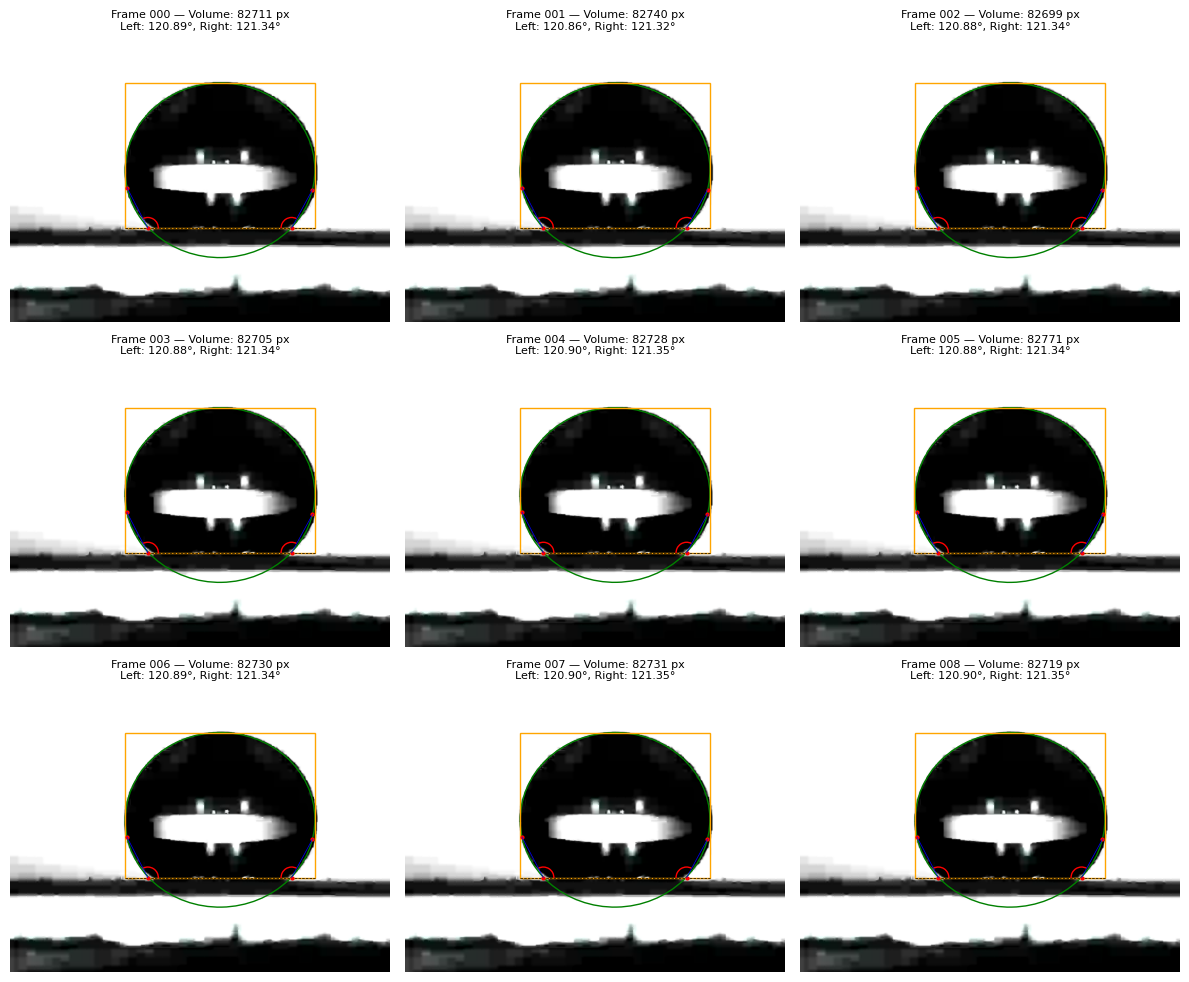

In [62]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Arc

def draw_contact_arc(ax, base, tip, angle_deg, radius=20, color='red'):
    def angle_between(p1, p2):
        return np.degrees(np.arctan2(p2[1] - p1[1], p2[0] - p1[0])) % 360

    theta1 = angle_between(base, tip)
    if tip[0] > base[0]:
        theta2 = (theta1 - angle_deg) % 360
    else:
        theta2 = (theta1 + angle_deg) % 360

    if (theta2 - theta1) % 360 > 180:
        theta1, theta2 = theta2, theta1

    arc = Arc(base, 2*radius, 2*radius, angle=0, theta1=theta1, theta2=theta2,
              color=color, lw=1)
    ax.add_patch(arc)

def draw_processed_output_from_dropnet(ax, image, output, frame_id):
    left_angle, right_angle, volume, xc, yc, a, b, theta_deg, x, y, w, h = output
    theta_rad = np.radians(theta_deg)
    cos_t, sin_t = np.cos(theta_rad), np.sin(theta_rad)
    t = np.linspace(0, 2*np.pi, 720)
    xt = a * np.cos(t)
    yt = b * np.sin(t)
    xe = xc + xt * cos_t - yt * sin_t
    ye = yc + xt * sin_t + yt * cos_t

    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.add_patch(patches.Ellipse((xc, yc), 2*a, 2*b, angle=theta_deg, edgecolor='green', facecolor='none', lw=1))
    ax.plot([x, x + w], [y + h, y + h], color='black', linestyle='--', lw=0.5)
    ax.add_patch(patches.Rectangle((x, y), w, h, edgecolor='orange', facecolor='none', lw=1))

    bottom_y = y + h
    contacts = [(x_, y_) for x_, y_ in zip(xe, ye) if abs(y_ - bottom_y) <= 2]
    contacts = sorted(contacts, key=lambda p: p[0])
    left_surface = (contacts[0][0], bottom_y) if contacts else (x, bottom_y)
    right_surface = (contacts[-1][0], bottom_y) if len(contacts) > 1 else (x + w, bottom_y)

    side_eps = 5
    ellipse_pts = list(zip(xe, ye))
    left_candidates = [pt for pt in ellipse_pts if abs(pt[0] - x) <= side_eps and y <= pt[1] <= y + h]
    right_candidates = [pt for pt in ellipse_pts if abs(pt[0] - (x + w)) <= side_eps and y <= pt[1] <= y + h]
    left_tangent = max(left_candidates, key=lambda pt: pt[1]) if left_candidates else left_surface
    right_tangent = max(right_candidates, key=lambda pt: pt[1]) if right_candidates else right_surface

    for pt in [left_surface, right_surface, left_tangent, right_tangent]:
        ax.plot(pt[0], pt[1], 'ro', markersize=2)

    ax.plot([left_surface[0], left_tangent[0]], [left_surface[1], left_tangent[1]], color='blue', lw=0.5)
    ax.plot([right_surface[0], right_tangent[0]], [right_surface[1], right_tangent[1]], color='blue', lw=0.5)

    draw_contact_arc(ax, left_surface, left_tangent, left_angle)
    draw_contact_arc(ax, right_surface, right_tangent, right_angle)

    title=f"Frame {frame_id:03d} — Volume: {int(volume)} px\nLeft: {left_angle:.2f}°, Right: {right_angle:.2f}°"
    ax.set_title(title, fontsize=8)
    ax.axis('off')

def run_dropnet_on_multiple_frames(frame_paths, model_path="dropnet_multitask.pth", scaler_path="scaler.joblib"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Load model
    seg_model = deeplabv3_mobilenet_v3_large(pretrained=False, aux_loss=True)
    seg_model.classifier[4] = torch.nn.Conv2d(256, 1, kernel_size=1)
    regressor = DropletCNNRegressor()
    model = DropNET(seg_model, regressor).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    scaler = joblib.load(scaler_path)

    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((240, 320)),
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
    ])

    fig, axs = plt.subplots(3, 3, figsize=(12, 10))
    axs = axs.flatten()

    for i, path in enumerate(frame_paths):
        image = cv2.imread(path, cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        tensor = transform(rgb).unsqueeze(0).to(device)

        with torch.no_grad():
            _, reg_out = model(tensor)
        reg_out = reg_out.squeeze().cpu().numpy()
        reg_out = scaler.inverse_transform(reg_out.reshape(1, -1)).flatten()

        frame_num = int(path.split("_")[-1].split(".")[0])
        draw_processed_output_from_dropnet(axs[i], image, reg_out, frame_num)

    plt.tight_layout()
    plt.show()


paths = [f"frames/frame_{i:03d}.png" for i in range(9)]
run_dropnet_on_multiple_frames(paths)


#### **Output Data Analysis**

In [81]:
import pandas as pd
from glob import glob
import re

def generate_dropnet_analysis_csv(frame_dir="frames", model_path="dropnet_multitask.pth", scaler_path="scaler.joblib", output_csv="dropnet_analysis.csv"):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Load model and scaler (reuse your existing setup)
    seg_model = deeplabv3_mobilenet_v3_large(pretrained=False, aux_loss=True)
    seg_model.classifier[4] = torch.nn.Conv2d(256, 1, kernel_size=1)
    regressor = DropletCNNRegressor()
    model = DropNET(seg_model, regressor).to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    scaler = joblib.load(scaler_path)

    # Preprocessing
    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((240, 320)),
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
    ])

    # Collect frames
    frame_paths = sorted(glob(os.path.join(frame_dir, "frame_*.png")))
    results = []

    for path in tqdm(frame_paths, desc="Generating CSV"):
        image = cv2.imread(path, cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        tensor = transform(rgb).unsqueeze(0).to(device)

        with torch.no_grad():
            _, reg_out = model(tensor)
        reg_out = reg_out.squeeze().cpu().numpy()
        reg_out = scaler.inverse_transform(reg_out.reshape(1, -1)).flatten()
        # Extract frame number from filename
        match = re.search(r"frame_(\d+)\.png", path)
        frame_id = int(match.group(1)) if match else -1

        results.append({
            "Frame": frame_id,
            "Left_Angle": reg_out[0],
            "Right_Angle": reg_out[1],
            "Volume": reg_out[2],
            "Ellipse_XC": reg_out[3],
            "Ellipse_YC": reg_out[4],
            "Ellipse_A": reg_out[5],
            "Ellipse_B": reg_out[6],
            "Ellipse_Theta": reg_out[7],
            "BBox_X": reg_out[8],
            "BBox_Y": reg_out[9],
            "BBox_W": reg_out[10],
            "BBox_H": reg_out[11],
        })

    # Save to CSV
    df = pd.DataFrame(results).sort_values("Frame")
    df["Volume_Loss"] = df["Volume"].diff().fillna(0).abs()
    df.to_csv(output_csv, index=False)
    print(f"[✓] Saved DropNET analysis to {output_csv}")

generate_dropnet_analysis_csv()



c:\Users\alesa\Desktop\Magistrale\ESILV\Second Semester\PI2\droplet-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\alesa\Desktop\Magistrale\ESILV\Second Semester\PI2\droplet-ml\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
C:\Users\alesa\AppData\Local\Temp\ipykernel_14960\2673921460.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#unt

[✓] Saved DropNET analysis to dropnet_analysis.csv


,Left_Angle,Right_Angle,Volume,Volume_Loss,Ellipse_XC,Ellipse_YC,Ellipse_A,Ellipse_B,Ellipse_Theta,BBox_X,BBox_Y,BBox_W,BBox_H,Ellipse_Aspect_Ratio,BBox_Aspect_Ratio
mean,119.797447,120.300138,66695.552848,5.805033,402.092530,266.906308,161.569097,150.981032,-0.550644,238.895418,115.316060,325.606445,245.469251,1.070459,1.327218
std,1.817839,1.810213,6046.895671,44.800658,12.131633,7.087810,7.075136,7.032232,1.945813,17.944300,12.518376,14.415600,12.467572,0.020050,0.031746
min,114.729126,115.694340,53686.566000,-682.540000,393.772860,250.613750,143.706330,134.068150,-5.241097,216.425960,85.745400,288.413400,222.417800,1.013785,1.277776
max,122.169450,122.711990,82771.670000,479.540000,428.376740,275.825350,179.768500,165.463270,5.465921,282.850220,137.294170,361.065030,274.946620,1.087549,1.375793


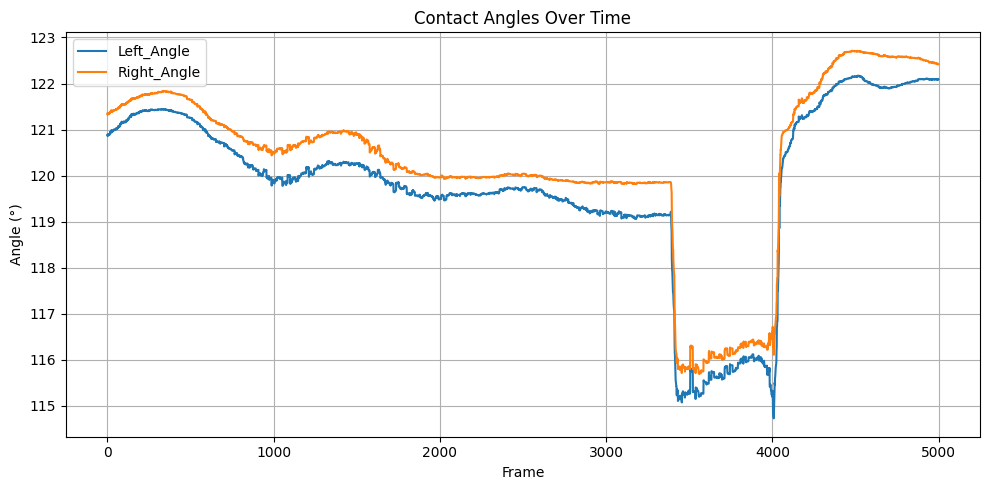

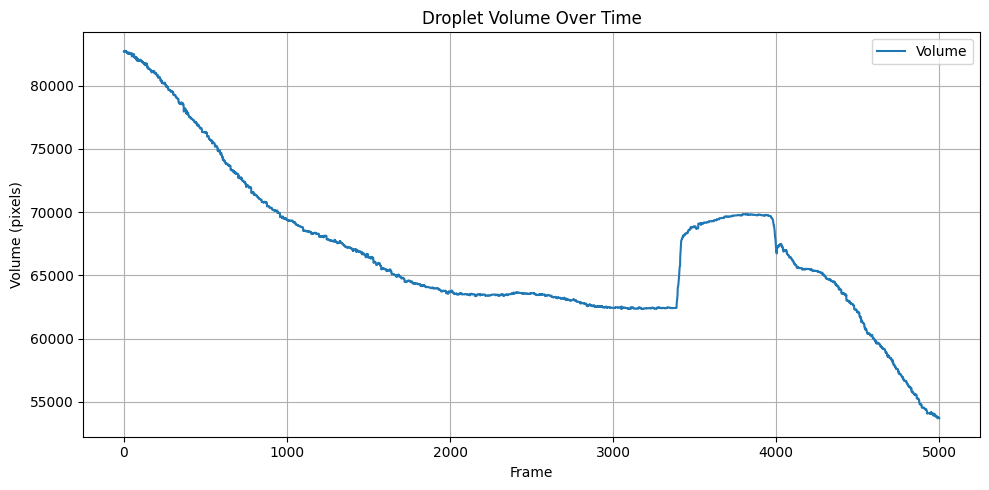

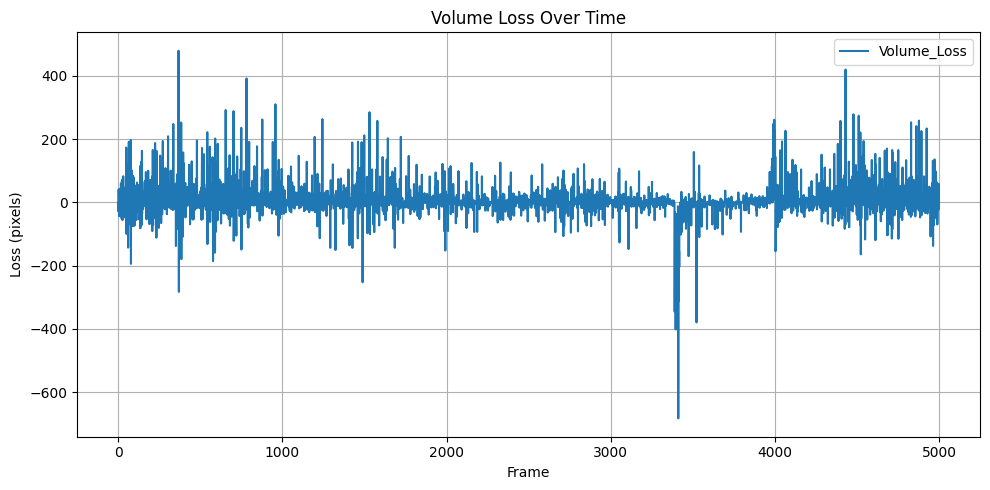

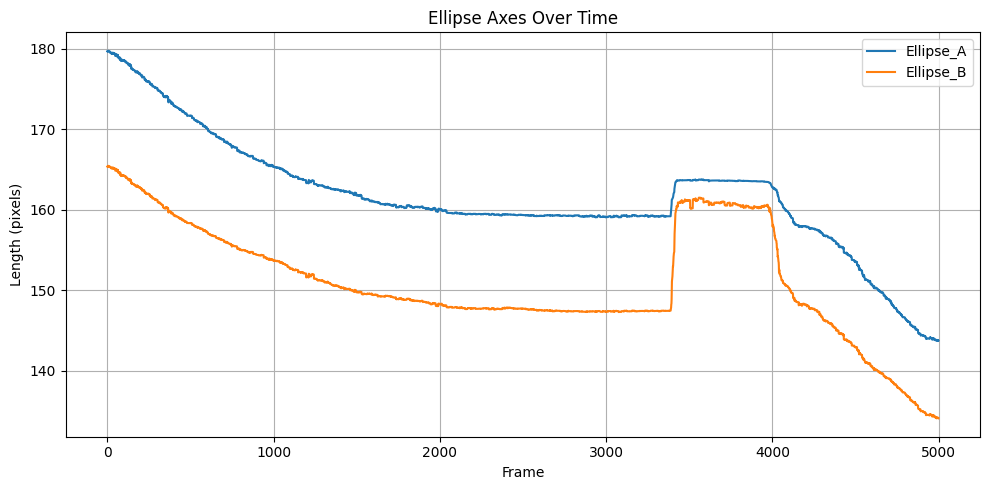

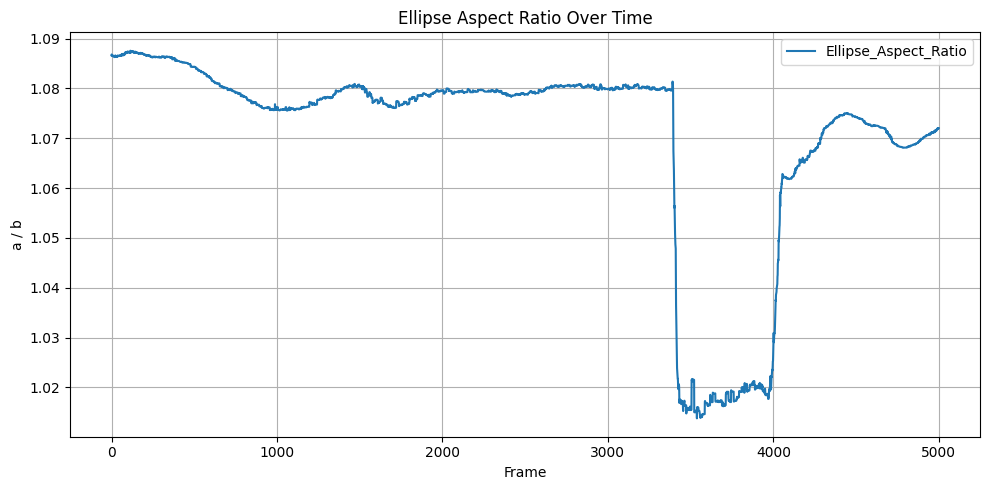

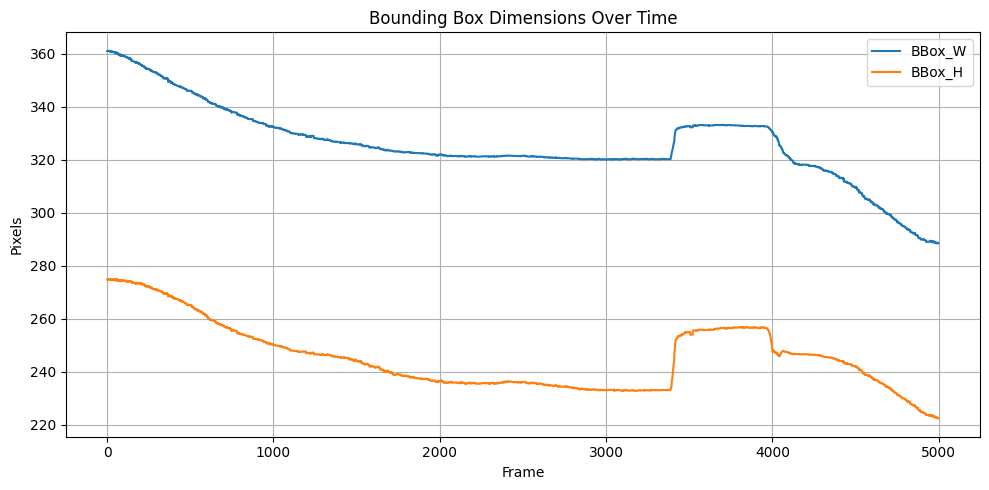

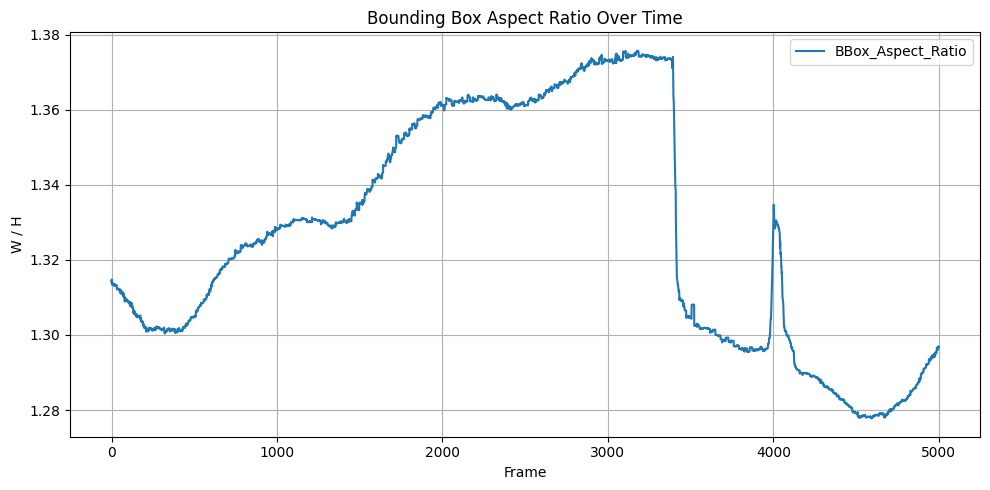

In [96]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Load and clean data
csv_path = "dropnet_analysis.csv"
df = pd.read_csv(csv_path)

# Ensure correct numeric types
df["Frame"] = pd.to_numeric(df["Frame"], errors="coerce")
for col in [
    "Left_Angle", "Right_Angle", "Volume",
    "Ellipse_A", "Ellipse_B", "BBox_W", "BBox_H"
]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Sort and reset index
df = df.sort_values("Frame").reset_index(drop=True)

# Derived features
df["Volume_Loss"] = df["Volume"].diff().fillna(0) * -1
df["Ellipse_Aspect_Ratio"] = df["Ellipse_A"] / df["Ellipse_B"]
df["BBox_Aspect_Ratio"] = df["BBox_W"] / df["BBox_H"]

# Summary statistics (printed directly)
numeric_columns = [
    "Left_Angle", "Right_Angle", "Volume", "Volume_Loss",
    "Ellipse_XC", "Ellipse_YC", "Ellipse_A", "Ellipse_B", "Ellipse_Theta",
    "BBox_X", "BBox_Y", "BBox_W", "BBox_H",
    "Ellipse_Aspect_Ratio", "BBox_Aspect_Ratio"
]
summary_stats = df[numeric_columns].describe().loc[["mean", "std", "min", "max"]]
display(summary_stats)

# Plotting utility
def show_line_plot(data, cols, title, ylabel):
    plt.figure(figsize=(10, 5))
    for col in cols:
        plt.plot(data["Frame"], data[col], label=col)
    plt.title(title)
    plt.xlabel("Frame")
    plt.ylabel(ylabel)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Show all plots
show_line_plot(df, ["Left_Angle", "Right_Angle"], "Contact Angles Over Time", "Angle (°)")
show_line_plot(df, ["Volume"], "Droplet Volume Over Time", "Volume (pixels)")
show_line_plot(df, ["Volume_Loss"], "Volume Loss Over Time", "Loss (pixels)")
show_line_plot(df, ["Ellipse_A", "Ellipse_B"], "Ellipse Axes Over Time", "Length (pixels)")
show_line_plot(df, ["Ellipse_Aspect_Ratio"], "Ellipse Aspect Ratio Over Time", "a / b")
show_line_plot(df, ["BBox_W", "BBox_H"], "Bounding Box Dimensions Over Time", "Pixels")
show_line_plot(df, ["BBox_Aspect_Ratio"], "Bounding Box Aspect Ratio Over Time", "W / H")
